# Семантическое обогащение данных о местах

В работе используется выборка московских POI из OpenStreetMap. Из исходных тегов строятся признаки для рекомендаций, после чего сравнивается поиск по исходным и обогащённым данным.

## 1. Окружение

Здесь устанавливаются библиотеки, фиксируется seed и задаются пути к сохранённым данным.

In [1]:
%pip install -q "pandas==3.1.0" "numpy==2.5.4" "scikit-learn==1.9.1" "matplotlib==3.11.2" "seaborn==0.13.2" "requests==2.32.5" "sentence-transformers==6.2.0"



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import platform
import random
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
RAW_PATH = Path("places_raw.csv")
ENRICHED_PATH = Path("places_enriched.csv")
QUERIES_PATH = Path("place_queries.csv")
RESULTS_PATH = Path("search_results_comparison.csv")

print("Python:", platform.python_version())
for package in ["pandas", "numpy", "scikit-learn", "sentence-transformers"]:
    print(f"{package}: {version(package)}")


Python: 3.12.5
pandas: 3.1.0
numpy: 2.5.4
scikit-learn: 1.9.1
sentence-transformers: 6.2.0


## 2. Получение и отбор мест

Снимок OpenStreetMap загружается из `places_raw.csv`, поэтому обычный запуск не обращается к API. Повторный сбор включается отдельным параметром и нужен только для обновления данных.


In [3]:
import time
from datetime import date

import requests

NOMINATIM_URL = "https://nominatim.openstreetmap.org/search"
USER_AGENT = "vk-internship-poi-project/1.0 (educational project)"
VIEWBOX = "37.2,56.0,38.0,55.5"
CATEGORY_QUERIES = {
    "cafe": "кафе, Москва",
    "restaurant": "ресторан, Москва",
    "museum": "музей, Москва",
    "park": "парк, Москва",
    "theatre": "театр, Москва",
    "library": "библиотека, Москва",
    "cinema": "кинотеатр, Москва",
}

def collect_nominatim_snapshot(queries=CATEGORY_QUERIES, limit=10, delay=1.1):
    session = requests.Session()
    session.headers.update({"User-Agent": USER_AGENT})
    rows = []
    for category, query in queries.items():
        response = session.get(NOMINATIM_URL, params={
            "q": query,
            "format": "jsonv2",
            "addressdetails": 1,
            "extratags": 1,
            "namedetails": 1,
            "bounded": 1,
            "viewbox": VIEWBOX,
            "limit": limit,
        }, timeout=30)
        response.raise_for_status()
        for item in response.json():
            address = item.get("address", {})
            tags = item.get("extratags", {})
            osm_type, osm_id = item["osm_type"], item["osm_id"]
            rows.append({
                "poi_id": f"{osm_type}/{osm_id}",
                "name": item.get("namedetails", {}).get("name") or item.get("name") or item["display_name"].split(",")[0],
                "category": category,
                "city": address.get("city") or address.get("town") or address.get("municipality", ""),
                "district": address.get("city_district") or address.get("borough") or address.get("suburb", ""),
                "address": item.get("display_name", ""),
                "latitude": float(item["lat"]),
                "longitude": float(item["lon"]),
                "opening_hours": tags.get("opening_hours", ""),
                "cuisine": tags.get("cuisine", ""),
                "wheelchair": tags.get("wheelchair", ""),
                "outdoor_seating": tags.get("outdoor_seating", ""),
                "internet_access": tags.get("internet_access", ""),
                "website": tags.get("website") or tags.get("contact:website", ""),
                "wikidata": tags.get("wikidata", ""),
                "wikipedia": tags.get("wikipedia", ""),
                "osm_url": f"https://www.openstreetmap.org/{osm_type}/{osm_id}",
                "source": "OpenStreetMap via Nominatim",
                "source_license": "ODbL 1.0",
                "retrieved_at": date.today().isoformat(),
                "raw_tags": json.dumps(tags, ensure_ascii=False, sort_keys=True),
            })
        time.sleep(delay)
    return pd.DataFrame(rows).drop_duplicates("poi_id").reset_index(drop=True)

def load_snapshot(path, refresh=False):
    if refresh:
        snapshot = collect_nominatim_snapshot()
        snapshot.to_csv(path, index=False)
        return snapshot
    if path.exists():
        return pd.read_csv(path).fillna("")
    raise FileNotFoundError(f"Missing snapshot: {path.resolve()}")

raw_snapshot = load_snapshot(RAW_PATH)
required = {
    "poi_id", "name", "category", "city", "address", "latitude", "longitude",
    "osm_url", "source", "source_license", "retrieved_at", "raw_tags",
}
if not required <= set(raw_snapshot.columns):
    raise ValueError("The POI snapshot has an unexpected schema")

inside_moscow = raw_snapshot["address"].str.contains("Москва", case=False, na=False) & ~raw_snapshot["address"].str.contains("Московская область", case=False, na=False)
park_names = raw_snapshot["name"].str.contains(r"парк|сад|сквер|заказник|холм|бульвар|набережн|лес", case=False, na=False)
is_place = raw_snapshot["category"].ne("park") | park_names
places_raw = raw_snapshot.loc[inside_moscow & is_place].drop_duplicates("poi_id").reset_index(drop=True)
rejected = raw_snapshot.loc[~(inside_moscow & is_place), ["name", "category", "address"]]

if not 50 <= len(places_raw) <= 100 or not places_raw["poi_id"].is_unique:
    raise ValueError("The filtered snapshot must contain 50–100 unique places")

category_counts = places_raw["category"].value_counts().sort_index()
print(f"Raw rows: {len(raw_snapshot)}")
print(f"Selected places: {len(places_raw)}")
print(f"Rejected rows: {len(rejected)}")
display(category_counts.to_frame("places"))
rejected


Raw rows: 70
Selected places: 63
Rejected rows: 7


,places
category,
cafe,10
cinema,9
library,10
museum,10
park,5
restaurant,10
theatre,9


,name,category,address
34,Можайский район,park,"Можайский район, Москва, Центральный федеральн..."
35,район Марьино,park,"район Марьино, Москва, Центральный федеральный..."
36,Захарьино,park,"Захарьино, район Щербинка, Москва, Центральный..."
37,район Крылатское,park,"район Крылатское, Москва, Центральный федераль..."
39,район Кунцево,park,"район Кунцево, Москва, Центральный федеральный..."
44,ФЭСТ,theatre,"ФЭСТ, 6А, улица Щербакова, Тайнинка, Мытищи, г..."
60,Mori Cinema,cinema,"Mori Cinema, улица Мира, Ядреево, Мытищи, горо..."


## 3. Семантические признаки

Для каждой категории задаётся один компактный профиль: тип опыта, атмосфера, сценарий посещения, время и русские поисковые термины. Доступные OSM-теги дополняют профиль сведениями о Wi-Fi, террасе и доступности.


In [4]:
PROFILE_COLUMNS = [
    "category", "label", "experience_types", "atmospheres",
    "visit_contexts", "visit_times", "search_terms",
]
PROFILE_ROWS = [
    ("museum", "музей", "culture|education", "calm|indoor", "family|weekend", "day|weekend", "музей выставка культура образование спокойно семья выходные"),
    ("cafe", "кафе", "food|work", "cozy|indoor", "work|friends", "morning|day", "кафе кофе еда работа уютное ноутбук друзья утро"),
    ("restaurant", "ресторан", "food|social", "cozy|social", "friends|date", "day|evening", "ресторан ужин еда уютное романтическое свидание друзья вечер"),
    ("park", "парк", "walk|nature", "outdoor|calm|quiet", "family|walk", "day|weekend", "парк прогулка природа на улице спокойно тихое семья выходные отдых"),
    ("theatre", "театр", "culture|entertainment", "cultural|indoor", "date|evening", "evening", "театр спектакль культура развлечение романтическое свидание вечер"),
    ("library", "библиотека", "education|work", "quiet|indoor", "work|alone", "day", "библиотека чтение образование работа тихое спокойно одному отдых"),
    ("cinema", "кинотеатр", "culture|entertainment", "entertainment|indoor", "friends|date", "day|evening", "кино кинотеатр фильм развлечение романтическое друзья свидание вечер"),
]
category_profiles = pd.DataFrame(PROFILE_ROWS, columns=PROFILE_COLUMNS).set_index("category")
for column in ["experience_types", "atmospheres", "visit_contexts", "visit_times"]:
    category_profiles[column] = category_profiles[column].str.split("|")

TAG_SIGNALS = [
    ("outdoor_seating", {"yes"}, "atmospheres", "outdoor", "на улице терраса"),
    ("internet_access", {"yes", "wlan", "wifi"}, "visit_contexts", "work", "работа wi-fi ноутбук"),
    ("wheelchair", {"yes"}, "visit_contexts", "accessible", "доступность коляска"),
]

def extract_features(row):
    profile = category_profiles.loc[row.category]
    features = {
        field: list(profile[field])
        for field in ["experience_types", "atmospheres", "visit_contexts", "visit_times"]
    }
    evidence = [f"category={row.category}"]
    search_terms = [profile["search_terms"]]
    for source, accepted, target, value, terms in TAG_SIGNALS:
        if str(getattr(row, source)).lower() in accepted:
            features[target].append(value)
            evidence.append(f"{source}={getattr(row, source)}")
            search_terms.append(terms)
    completeness_fields = [row.opening_hours, row.cuisine, row.wheelchair, row.website, row.wikidata, row.wikipedia]
    return {
        **{field: list(dict.fromkeys(values)) for field, values in features.items()},
        "budget": "unknown",
        "metadata_completeness": np.mean([bool(value) for value in completeness_fields]),
        "feature_evidence": evidence,
        "available_tags": sorted(json.loads(row.raw_tags)) if row.raw_tags else [],
        "semantic_search_terms": " ".join(search_terms),
    }

places = pd.concat([
    places_raw.reset_index(drop=True),
    pd.DataFrame(extract_features(row) for row in places_raw.itertuples(index=False)),
], axis=1)

def make_description(row):
    district = f" в районе {row.district}" if row.district else " в Москве"
    details = [value for value in [
        f"кухня: {row.cuisine}" if row.cuisine else "",
        f"часы работы: {row.opening_hours}" if row.opening_hours else "",
    ] if value]
    suffix = f" Дополнительно: {'; '.join(details)}." if details else ""
    return f"{row['name']} — {category_profiles.loc[row.category, 'label']}{district}. {row.semantic_search_terms}.{suffix}"

places["description"] = places.apply(make_description, axis=1)
enriched_export = places.copy()
for column in ["experience_types", "atmospheres", "visit_contexts", "visit_times", "feature_evidence", "available_tags"]:
    enriched_export[column] = enriched_export[column].map(lambda values: json.dumps(values, ensure_ascii=False))
enriched_export.to_csv(ENRICHED_PATH, index=False)
display(places.head()[["name", "category", "description", "feature_evidence"]])


,name,category,description,feature_evidence
0,Государственный Дарвиновский музей,museum,Государственный Дарвиновский музей — музей в р...,[category=museum]
1,Государственный геологический музей им. В. И. ...,museum,Государственный геологический музей им. В. И. ...,[category=museum]
2,Всероссийский музей декоративно-прикладного и ...,museum,Всероссийский музей декоративно-прикладного и ...,[category=museum]
3,Art Future Gallery,museum,Art Future Gallery — музей в районе район Черт...,[category=museum]
4,Мемориальный музей А. Н. Скрябина,museum,Мемориальный музей А. Н. Скрябина — музей в ра...,[category=museum]


## 4. Проверка и EDA

Считается полнота дополнительных OSM-полей. Графики показывают состав выборки и частотность многозначных семантических признаков.

In [5]:
coverage = places[[
    "opening_hours", "cuisine", "wheelchair", "website", "wikidata", "wikipedia"
]].ne("").mean().rename("coverage")
coverage.to_frame().round(3)


,coverage
opening_hours,0.571
cuisine,0.206
wheelchair,0.048
website,0.587
wikidata,0.302
wikipedia,0.222


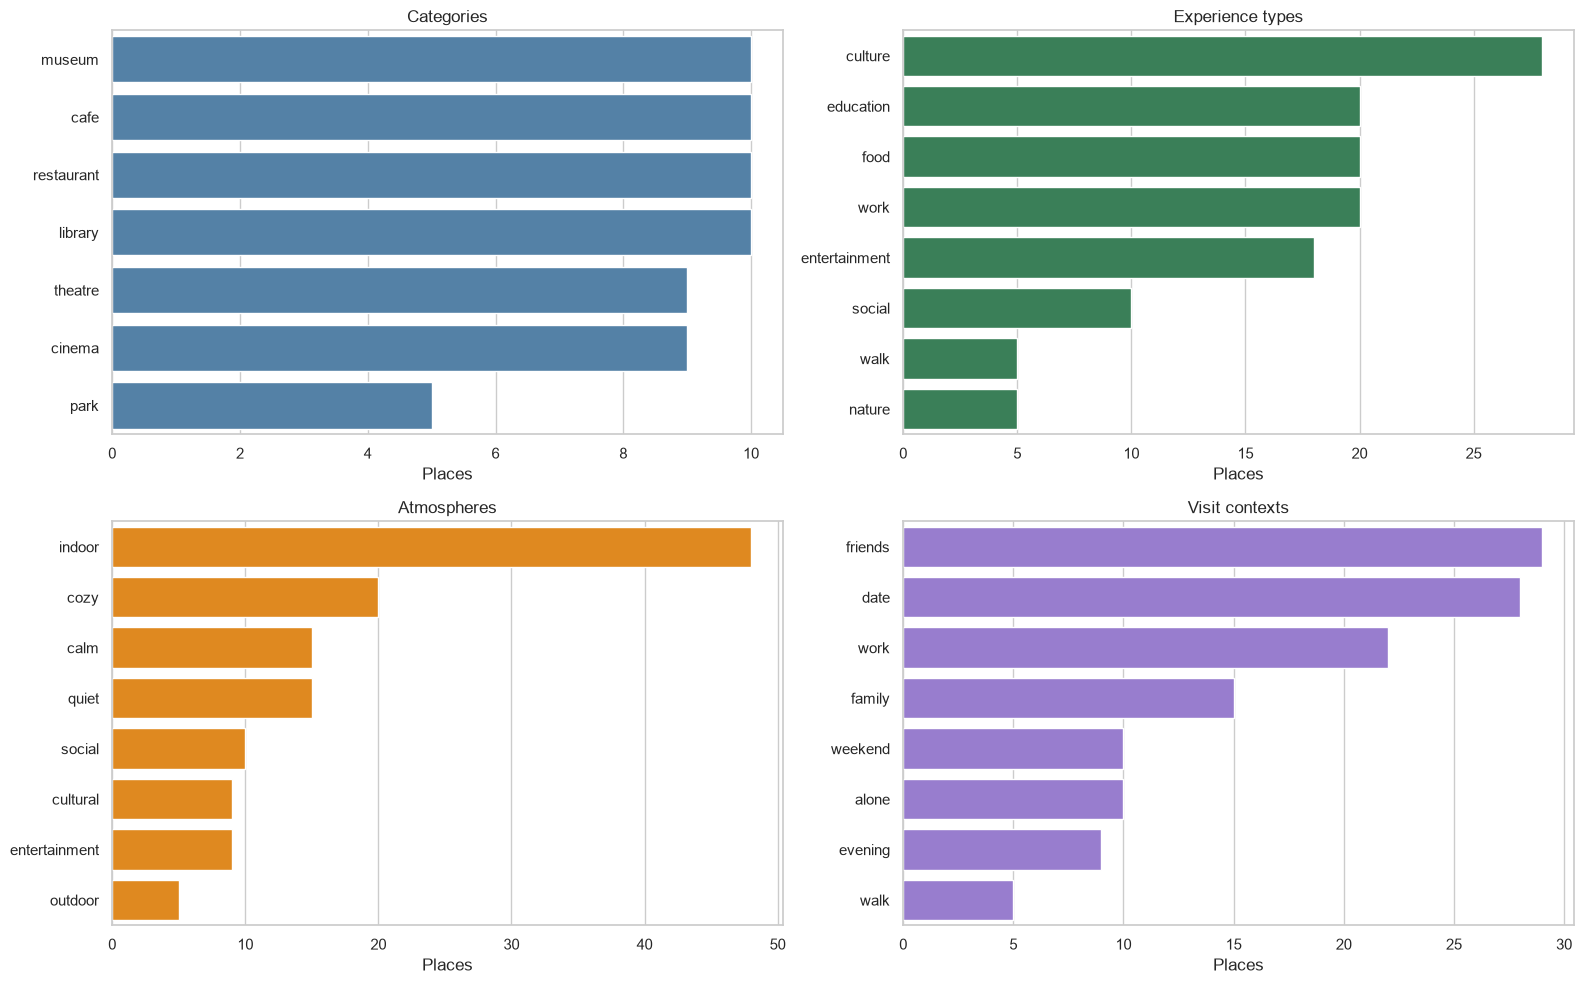

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

category_counts = places["category"].value_counts()
sns.barplot(x=category_counts.values, y=category_counts.index, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Categories")
axes[0, 0].set_xlabel("Places")
axes[0, 0].set_ylabel("")

experience_counts = places.explode("experience_types")["experience_types"].value_counts()
sns.barplot(x=experience_counts.values, y=experience_counts.index, ax=axes[0, 1], color="seagreen")
axes[0, 1].set_title("Experience types")
axes[0, 1].set_xlabel("Places")
axes[0, 1].set_ylabel("")

atmosphere_counts = places.explode("atmospheres")["atmospheres"].value_counts()
sns.barplot(x=atmosphere_counts.values, y=atmosphere_counts.index, ax=axes[1, 0], color="darkorange")
axes[1, 0].set_title("Atmospheres")
axes[1, 0].set_xlabel("Places")
axes[1, 0].set_ylabel("")

context_counts = places.explode("visit_contexts")["visit_contexts"].value_counts()
sns.barplot(x=context_counts.values, y=context_counts.index, ax=axes[1, 1], color="mediumpurple")
axes[1, 1].set_title("Visit contexts")
axes[1, 1].set_xlabel("Places")
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()

## 5. Поиск

Сравниваются два локальных TF-IDF baseline и multilingual E5. Модель строит эмбеддинги только по исходным метаданным места, а ручные категории и семантика из `place_queries.csv` используются исключительно при расчёте метрик.


In [7]:
from functools import partial

from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.pipeline import FeatureUnion

SEARCH_CUTOFFS = (5, 10, 15)
EMBEDDING_MODEL_ID = "intfloat/multilingual-e5-small"
EMBEDDING_MODEL_REVISION = "fd1525a9fd15316a2d503bf26ab031a61d056e98"

places["metadata_text"] = places.apply(
    lambda row: " ".join(str(value) for value in [
        row["name"], category_profiles.loc[row.category, "label"],
        row.cuisine, row.district, row.address,
    ] if value),
    axis=1,
)
places["enriched_text"] = places["metadata_text"] + " " + places["semantic_search_terms"]
places["embedding_text"] = places.apply(
    lambda row: ". ".join(str(value) for value in [
        row["name"],
        f"тип места: {category_profiles.loc[row.category, 'label']}",
        f"район: {row.district}" if row.district else "",
        f"кухня: {row.cuisine}" if row.cuisine else "",
    ] if value),
    axis=1,
)

tfidf_spaces = {}
for method, column in {
    "metadata_tfidf": "metadata_text",
    "enriched_tfidf": "enriched_text",
}.items():
    vectorizer = FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)),
    ])
    tfidf_spaces[method] = (vectorizer, vectorizer.fit_transform(places[column]))

embedding_model = SentenceTransformer(
    EMBEDDING_MODEL_ID,
    revision=EMBEDDING_MODEL_REVISION,
    device="cpu",
)
document_embeddings = embedding_model.encode(
    [f"passage: {text}" for text in places["embedding_text"]],
    batch_size=32,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True,
)
np.savez_compressed(
    "place_embeddings.npz",
    poi_id=places["poi_id"].to_numpy(),
    embedding=document_embeddings,
)

def tfidf_scores(query, space):
    vectorizer, matrix = space
    return cosine_similarity(vectorizer.transform([query]), matrix).ravel()

def embedding_scores(query):
    query_embedding = embedding_model.encode(
        [f"query: {query}"],
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=False,
    )[0]
    return document_embeddings @ query_embedding

search_scorers = {
    method: partial(tfidf_scores, space=space)
    for method, space in tfidf_spaces.items()
}
search_scorers["e5"] = embedding_scores

def search_places(query, method, k=max(SEARCH_CUTOFFS)):
    scores = search_scorers[method](query)
    order = np.argsort(-scores)[:k]
    result = places.iloc[order][["poi_id", "name", "category", "description", "osm_url"]].copy()
    result["score"] = scores[order]
    return result

query_specs = pd.read_csv(QUERIES_PATH).fillna("")
for column in ["categories", "semantics"]:
    query_specs[column] = query_specs[column].map(lambda value: frozenset(filter(None, value.split("|"))))

def reference_relevance(row, categories, semantics):
    row_semantics = set(row.experience_types) | set(row.atmospheres) | set(row.visit_contexts) | set(row.visit_times)
    return int(row.category in categories and semantics.issubset(row_semantics))

result_rows = []
for spec in query_specs.itertuples(index=False):
    total_relevant = sum(
        reference_relevance(row, spec.categories, spec.semantics)
        for row in places.itertuples(index=False)
    )
    for method in search_scorers:
        result = search_places(spec.query, method)
        for rank, row in enumerate(result.itertuples(index=False), start=1):
            source_row = places.loc[places["poi_id"] == row.poi_id].iloc[0]
            result_rows.append({
                "query_id": spec.query_id,
                "query": spec.query,
                "method": method,
                "rank": rank,
                "poi_id": row.poi_id,
                "name": row.name,
                "category": row.category,
                "score": row.score,
                "reference_relevance": reference_relevance(source_row, spec.categories, spec.semantics),
                "total_relevant_in_corpus": total_relevant,
                "osm_url": row.osm_url,
            })

search_results = pd.DataFrame(result_rows)
relevant_at_max = search_results.groupby(["query_id", "method"])["reference_relevance"].transform("sum").astype(int)
search_results["analysis"] = relevant_at_max.astype(str) + f"/{max(SEARCH_CUTOFFS)} relevant results"
search_results.to_csv(RESULTS_PATH, index=False)
search_results.head(10)


/Users/maksim/university/VK/Playlist generation/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1025 19:57:06.312000 72292 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Batches: 100%|██████████| 2/2 [00:00<00:00, 16.41it/s]


,query_id,query,method,rank,poi_id,name,category,score,reference_relevance,total_relevant_in_corpus,osm_url,analysis
0,q01,Ламповое кафе где можно поработать с ноутбуком,metadata_tfidf,1,way/857873932,Юг,cafe,0.123333,1,10,https://www.openstreetmap.org/way/857873932,10/15 relevant results
1,q01,Ламповое кафе где можно поработать с ноутбуком,metadata_tfidf,2,node/9844166488,Zefir,cafe,0.119488,1,10,https://www.openstreetmap.org/node/9844166488,10/15 relevant results
2,q01,Ламповое кафе где можно поработать с ноутбуком,metadata_tfidf,3,node/11425792243,Plim Coffee,cafe,0.111793,1,10,https://www.openstreetmap.org/node/11425792243,10/15 relevant results
3,q01,Ламповое кафе где можно поработать с ноутбуком,metadata_tfidf,4,node/10576689469,CofeFest,cafe,0.111063,1,10,https://www.openstreetmap.org/node/10576689469,10/15 relevant results
4,q01,Ламповое кафе где можно поработать с ноутбуком,metadata_tfidf,5,node/5643723647,Costa,cafe,0.108205,1,10,https://www.openstreetmap.org/node/5643723647,10/15 relevant results
5,q01,Ламповое кафе где можно поработать с ноутбуком,metadata_tfidf,6,node/7039315244,Cassette,cafe,0.101098,1,10,https://www.openstreetmap.org/node/7039315244,10/15 relevant results
6,q01,Ламповое кафе где можно поработать с ноутбуком,metadata_tfidf,7,node/10576689492,CofeFest,cafe,0.095289,1,10,https://www.openstreetmap.org/node/10576689492,10/15 relevant results
7,q01,Ламповое кафе где можно поработать с ноутбуком,metadata_tfidf,8,node/9841073871,Granvillano,cafe,0.095089,1,10,https://www.openstreetmap.org/node/9841073871,10/15 relevant results
8,q01,Ламповое кафе где можно поработать с ноутбуком,metadata_tfidf,9,node/13785336829,CoFFee Russ,cafe,0.094561,1,10,https://www.openstreetmap.org/node/13785336829,10/15 relevant results
9,q01,Ламповое кафе где можно поработать с ноутбуком,metadata_tfidf,10,node/3615331570,Coffee and the City,cafe,0.082513,1,10,https://www.openstreetmap.org/node/3615331570,10/15 relevant results


## 6. Оценка поиска

На 24 независимых запросах и глубинах 5, 10 и 15 считаются Precision, Recall, MAP, nDCG, MRR и HitRate. Запросы и эталонная разметка хранятся отдельно от алгоритма в `place_queries.csv`.


In [8]:
def ranking_metrics(values, total_relevant, k):
    hits = np.asarray(values[:k], dtype=float)
    ranks = np.arange(1, k + 1)
    cumulative = np.cumsum(hits)
    discounts = 1 / np.log2(ranks + 1)
    ideal = np.zeros(k)
    ideal[:min(total_relevant, k)] = 1
    return {
        "precision": float(hits.mean()),
        "recall": float(hits.sum() / total_relevant) if total_relevant else 0.0,
        "map": float(np.sum((cumulative / ranks) * hits) / min(total_relevant, k)) if total_relevant else 0.0,
        "ndcg": float(np.sum(hits * discounts) / np.sum(ideal * discounts)) if total_relevant else 0.0,
        "mrr": float(1 / ranks[np.flatnonzero(hits)[0]]) if hits.any() else 0.0,
        "hit_rate": float(hits.any()),
    }

metric_rows = []
for (query_id, method), group in search_results.groupby(["query_id", "method"]):
    ordered = group.sort_values("rank")
    total_relevant = int(ordered["total_relevant_in_corpus"].iloc[0])
    for k in SEARCH_CUTOFFS:
        metric_rows.append({
            "query_id": query_id,
            "method": method,
            "k": k,
            "total_relevant_in_corpus": total_relevant,
            **ranking_metrics(ordered["reference_relevance"].to_numpy(), total_relevant, k),
        })

search_metrics = pd.DataFrame(metric_rows)
metric_columns = ["precision", "recall", "map", "ndcg", "mrr", "hit_rate"]
summary_metrics = search_metrics.groupby(["method", "k"])[metric_columns].mean()
display(summary_metrics.round(3))
display(search_metrics.pivot_table(index=["query_id", "k"], columns="method", values="ndcg").round(3))


precision  recall    map   ndcg    mrr  hit_rate
method         k                                                   
e5             5       0.608   0.310  0.573  0.609  0.668     0.792
               10      0.513   0.510  0.473  0.558  0.683     0.917
               15      0.422   0.634  0.519  0.617  0.687     0.958
enriched_tfidf 5       0.792   0.415  0.742  0.777  0.795     0.917
               10      0.771   0.798  0.749  0.811  0.807     1.000
               15      0.594   0.904  0.788  0.851  0.807     1.000
metadata_tfidf 5       0.308   0.150  0.242  0.321  0.492     0.750
               10      0.325   0.317  0.219  0.335  0.517     0.958
               15      0.306   0.438  0.256  0.394  0.517     0.958

method          e5  enriched_tfidf  metadata_tfidf
query_id k                                        
q01      5   1.000           1.000           1.000
         10  0.860           1.000           1.000
         15  0.978           1.000           1.000
q02      5   1.000           1.000           0.000
         10  0.931           1.000           0.130
...            ...             ...             ...
q23      10  1.000           1.000           0.763
         15  0.913           1.000           0.774
q24      5   0.146           1.000           0.339
         10  0.247           0.867           0.363
         15  0.279           0.762           0.325

[72 rows x 3 columns]

In [9]:
for spec in query_specs.iloc[[0, 7, 22]].itertuples(index=False):
    print(spec.query)
    display(search_results[
        (search_results["query_id"] == spec.query_id)
        & (search_results["method"] == "e5")
        & (search_results["rank"] <= 5)
    ][["rank", "name", "category", "score", "reference_relevance"]])


Ламповое кафе где можно поработать с ноутбуком


,rank,name,category,score,reference_relevance
30,1,Plim Coffee,cafe,0.837799,1
31,2,Zefir,cafe,0.837760,1
32,3,Coffee and the City,cafe,0.835774,1
33,4,Costa,cafe,0.834999,1
34,5,CofeFest,cafe,0.833757,1


Куда пойти с детьми погулять


,rank,name,category,score,reference_relevance
345,1,Московский детский театр марионеток,theatre,0.827736,0
346,2,Синема Парк Тёплый Стан,cinema,0.827605,0
347,3,Планета КВН,theatre,0.826607,0
348,4,Детская библиотека № 60,library,0.825548,0
349,5,Крылатские холмы,park,0.824348,1


Спектакль или кино для вечера вдвоём


,rank,name,category,score,reference_relevance
1020,1,Саяны,cinema,0.847781,1
1021,2,Романов Синема,cinema,0.843404,1
1022,3,Garage Screen,cinema,0.842712,1
1023,4,Планета КВН,theatre,0.836380,1
1024,5,Кино Окко,cinema,0.836061,1


## 7. Выводы

TF-IDF показывает качество лексического baseline, а E5 проверяет, помогает ли семантическое представление на разговорных запросах и синонимах. Итоговый вывод делается по таблице метрик после запуска.


In [10]:
REFERENCE_K = 10
reference_metrics = summary_metrics.xs(REFERENCE_K, level="k")
best_method = reference_metrics["ndcg"].idxmax()
print(f"Places: {len(places)}")
print(f"Categories: {places['category'].nunique()}")
print(f"Search queries: {len(query_specs)}")
print(f"Best method by nDCG@{REFERENCE_K}: {best_method}")
display(summary_metrics.round(3))


Places: 63
Categories: 7
Search queries: 24
Best method by nDCG@10: enriched_tfidf


precision  recall    map   ndcg    mrr  hit_rate
method         k                                                   
e5             5       0.608   0.310  0.573  0.609  0.668     0.792
               10      0.513   0.510  0.473  0.558  0.683     0.917
               15      0.422   0.634  0.519  0.617  0.687     0.958
enriched_tfidf 5       0.792   0.415  0.742  0.777  0.795     0.917
               10      0.771   0.798  0.749  0.811  0.807     1.000
               15      0.594   0.904  0.788  0.851  0.807     1.000
metadata_tfidf 5       0.308   0.150  0.242  0.321  0.492     0.750
               10      0.325   0.317  0.219  0.335  0.517     0.958
               15      0.306   0.438  0.256  0.394  0.517     0.958